In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
!pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 16.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [3]:
import torch

print("GPU Available:", torch.cuda.is_available())
!nvidia-smi

GPU Available: True
Thu Nov 12 08:37:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   44C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------------

In [4]:
!mkdir -p "/content/drive/MyDrive/cv_project/dataset"

In [5]:
!ls "/content/drive/MyDrive"

 AIRI_Waste_Detection
'certificate 1.jpeg'
'certificate 2.jpeg'
'certificate 3.jpeg'
'certificate 4.jpeg'
 Classroom
'CNIC BACK SIDE.jpeg'
'Colab Notebooks'
 cv_project
'Cyber Security ZDA Final ReportV1.gdoc'
'FRIEND FUNCTIONS.pdf'
'https:  www.kaggle.com datasets hasibalmuzdadid g... (1).gsheet'
'https:  www.kaggle.com datasets hasibalmuzdadid g....gsheet'
'Individual'$'\n''Notebook Findings Report'$'\n''1. Notebook O....gsheet'
'Mahnoor (068 )chatnote.zip'
'MAHNOOR (068).docx'
'MAHNOOR(068).docx'
'MAHNOOR 068.xlsx'
'mahnoor  Su92-bscsm-s23-068 assignment no 2 coal theroy.docx'
 MAHNOOR.zip
 MyDrive
'plz give the count as well.gsheet'
'student card.jpeg'
'Untitled Diagram.drawio.png'
'WhatsApp Image 2025-02-09 at 2.09.58 PM.jpeg'


In [6]:
!ls "/content/drive/MyDrive/cv_project/dataset/final_dataset"


dataset_manifest.csv  data.yaml  images  labels


In [7]:
!cat "/content/drive/MyDrive/cv_project/dataset/final_dataset/data.yaml"

path: .
train: images/train
val: images/val
test: images/test

nc: 2
names:
  0: 'With Helmet'
  1: 'Without Helmet'


In [8]:
yaml_path = "/content/drive/MyDrive/cv_project/dataset/final_dataset/data.yaml"

with open(yaml_path, "r") as file:
    content = file.read()

content = content.replace(
    "path: .",
    "path: /content/drive/MyDrive/cv_project/dataset/final_dataset"
)

with open(yaml_path, "w") as file:
    file.write(content)

print("Dataset path updated successfully!")

Dataset path updated successfully!


In [9]:
from pathlib import Path
import yaml

yaml_path = Path("/content/drive/MyDrive/cv_project/dataset/final_dataset/data.yaml")

with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)

dataset_path = Path(data["path"])

for split in ["train", "val", "test"]:
    image_dir = dataset_path / data[split]
    print(f"{split}: {image_dir.exists()}")

print("Classes:", data["names"])

train: True
val: True
test: True
Classes: {0: 'With Helmet', 1: 'Without Helmet'}


In [10]:
from pathlib import Path

base = Path("/content/drive/MyDrive/cv_project/dataset/final_dataset")

for split in ["train", "val", "test"]:
    image_count = len(list((base / "images" / split).glob("*")))
    label_count = len(list((base / "labels" / split).glob("*.txt")))

    print(f"{split}: Images = {image_count}, Labels = {label_count}")

train: Images = 140, Labels = 140
val: Images = 40, Labels = 40
test: Images = 20, Labels = 20


In [11]:
from ultralytics import YOLO
import time

model = YOLO("yolov8n.pt")

start_time = time.time()

results = model.train(
    data="/content/drive/MyDrive/cv_project/dataset/final_dataset/data.yaml",
    epochs=30,
    imgsz=640,
    batch=8,
    pretrained=True,
    project="/content/drive/MyDrive/cv_project/outputs/training_results",
    name="yolov8n_baseline"
)

training_time = time.time() - start_time

print("Training completed!")
print(f"Training time: {training_time / 60:.2f} minutes")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/cv_project/dataset/final_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, 

In [12]:
!ls -lh "/content/drive/MyDrive/cv_project/outputs/training_results/yolov8n_baseline"

total 7.9M
-rw------- 1 root root 1.8K Nov 12 08:54 args.yaml
-rw------- 1 root root 151K Nov 12 08:58 BoxF1_curve.png
-rw------- 1 root root 177K Nov 12 08:58 BoxP_curve.png
-rw------- 1 root root 111K Nov 12 08:58 BoxPR_curve.png
-rw------- 1 root root 140K Nov 12 08:58 BoxR_curve.png
-rw------- 1 root root 131K Nov 12 08:58 confusion_matrix_normalized.png
-rw------- 1 root root 133K Nov 12 08:58 confusion_matrix.png
-rw------- 1 root root 137K Nov 12 08:56 labels.jpg
-rw------- 1 root root 3.9K Nov 12 08:58 results.csv
-rw------- 1 root root 290K Nov 12 08:58 results.png
-rw------- 1 root root 561K Nov 12 08:56 train_batch0.jpg
-rw------- 1 root root 440K Nov 12 08:56 train_batch1.jpg
-rw------- 1 root root 472K Nov 12 08:56 train_batch2.jpg
-rw------- 1 root root 354K Nov 12 08:57 train_batch360.jpg
-rw------- 1 root root 399K Nov 12 08:57 train_batch361.jpg
-rw------- 1 root root 449K Nov 12 08:57 train_batch362.jpg
-rw------- 1 root root 705K Nov 12 08:58 val_batch0_labels.jpg
-r

In [13]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/cv_project/outputs/training_results/yolov8n_baseline/weights/best.pt"
)

test_metrics = model.val(
    data="/content/drive/MyDrive/cv_project/dataset/final_dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=8,
    project="/content/drive/MyDrive/cv_project/outputs",
    name="test_evaluation"
)

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.6±0.2 ms, read: 0.1±0.0 MB/s, size: 36.1 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/cv_project/dataset/final_dataset/labels/test... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 1.0s/it 20.8s
val: New cache created: /content/drive/MyDrive/cv_project/dataset/final_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.9it/s 1.0s
                   all         20         89      0.698      0.596       0.65      0.277
           With Helmet         15         40      0.571        0.6      0.629      0.282
        Without Helmet         14        

In [14]:
!ls -lh "/content/drive/MyDrive/cv_project/outputs/test_evaluation"

total 3.4M
-rw------- 1 root root 156K Nov 12 09:02 BoxF1_curve.png
-rw------- 1 root root 141K Nov 12 09:02 BoxP_curve.png
-rw------- 1 root root 107K Nov 12 09:02 BoxPR_curve.png
-rw------- 1 root root 138K Nov 12 09:02 BoxR_curve.png
-rw------- 1 root root 129K Nov 12 09:02 confusion_matrix_normalized.png
-rw------- 1 root root 126K Nov 12 09:02 confusion_matrix.png
-rw------- 1 root root 555K Nov 12 09:02 val_batch0_labels.jpg
-rw------- 1 root root 572K Nov 12 09:02 val_batch0_pred.jpg
-rw------- 1 root root 498K Nov 12 09:02 val_batch1_labels.jpg
-rw------- 1 root root 492K Nov 12 09:02 val_batch1_pred.jpg
-rw------- 1 root root 265K Nov 12 09:02 val_batch2_labels.jpg
-rw------- 1 root root 262K Nov 12 09:02 val_batch2_pred.jpg


In [15]:
from ultralytics import YOLO

model = YOLO(
    "/content/drive/MyDrive/cv_project/outputs/training_results/yolov8n_baseline/weights/best.pt"
)

predictions = model.predict(
    source="/content/drive/MyDrive/cv_project/dataset/final_dataset/images/test",
    imgsz=640,
    conf=0.25,
    save=True,
    save_conf=True,
    project="/content/drive/MyDrive/cv_project/outputs",
    name="predictions"
)

print("Images processed:", len(predictions))
print("Predictions saved successfully!")


image 1/20 /content/drive/MyDrive/cv_project/dataset/final_dataset/images/test/manual__BikesHelmets115_png_jpg.rf.e2d44812a061abe2376fea5b3f9dcdc6.jpg: 640x640 10 With Helmets, 2 Without Helmets, 10.3ms
image 2/20 /content/drive/MyDrive/cv_project/dataset/final_dataset/images/test/manual__BikesHelmets118_png_jpg.rf.276fb4c4dc04d2bb205f3790db6968ff.jpg: 640x640 1 With Helmet, 7 Without Helmets, 13.6ms
image 3/20 /content/drive/MyDrive/cv_project/dataset/final_dataset/images/test/manual__BikesHelmets128_png_jpg.rf.689974532482e03a0a3b4362a02c8d3b.jpg: 640x640 2 Without Helmets, 10.7ms
image 4/20 /content/drive/MyDrive/cv_project/dataset/final_dataset/images/test/manual__BikesHelmets147_png_jpg.rf.325efbcc48fe92642606c8249b03f457.jpg: 640x640 3 With Helmets, 1 Without Helmet, 11.4ms
image 5/20 /content/drive/MyDrive/cv_project/dataset/final_dataset/images/test/manual__BikesHelmets215_png_jpg.rf.fce9fad0356efb7cb7b4453d8a231bcb.jpg: 640x640 5 With Helmets, 4 Without Helmets, 11.9ms
image 

In [16]:
!ls -lh "/content/drive/MyDrive/cv_project/outputs/predictions"

total 1.5M
-rw------- 1 root root 107K Nov 12 09:06 manual__BikesHelmets115_png_jpg.rf.e2d44812a061abe2376fea5b3f9dcdc6.jpg
-rw------- 1 root root 104K Nov 12 09:06 manual__BikesHelmets118_png_jpg.rf.276fb4c4dc04d2bb205f3790db6968ff.jpg
-rw------- 1 root root  78K Nov 12 09:06 manual__BikesHelmets128_png_jpg.rf.689974532482e03a0a3b4362a02c8d3b.jpg
-rw------- 1 root root  88K Nov 12 09:06 manual__BikesHelmets147_png_jpg.rf.325efbcc48fe92642606c8249b03f457.jpg
-rw------- 1 root root  95K Nov 12 09:06 manual__BikesHelmets215_png_jpg.rf.fce9fad0356efb7cb7b4453d8a231bcb.jpg
-rw------- 1 root root  75K Nov 12 09:06 manual__BikesHelmets237_png_jpg.rf.08fb7fd22dc6ebc33e1d52fe2975232c.jpg
-rw------- 1 root root  99K Nov 12 09:06 manual__BikesHelmets241_png_jpg.rf.fb3d09910d6fd3c901431a2b26da3cd4.jpg
-rw------- 1 root root  81K Nov 12 09:06 manual__BikesHelmets385_png_jpg.rf.2f8cd4db9a1de09e3b0876d07ddcce24.jpg
-rw------- 1 root root  64K Nov 12 09:06 manual__BikesHelmets480_png_jpg.rf.583ec5660

In [17]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

prediction_folder = Path(
    "/content/drive/MyDrive/cv_project/outputs/predictions"
)

images = sorted(prediction_folder.glob("*.jpg"))[:10]

fig, axes = plt.subplots(5, 2, figsize=(16, 25))

for ax, image_path in zip(axes.flatten(), images):
    img = Image.open(image_path)
    ax.imshow(img)
    ax.set_title(image_path.name[:35], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [18]:
from ultralytics import YOLO
from pathlib import Path

model = YOLO(
    "/content/drive/MyDrive/cv_project/outputs/training_results/yolov8n_baseline/weights/best.pt"
)

results = model.val(
    data="/content/drive/MyDrive/cv_project/dataset/final_dataset/data.yaml",
    split="test",
    imgsz=640,
    batch=8,
    plots=True,
    project="/content/drive/MyDrive/cv_project/outputs",
    name="error_analysis"
)

print("Test evaluation completed.")
print("Results saved in outputs/error_analysis")

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,132,950 parameters, 0 gradients, 8.6 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.3±0.1 ms, read: 40.6±5.7 MB/s, size: 37.3 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/cv_project/dataset/final_dataset/labels/test.cache... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 5.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 2.4it/s 1.3s
                   all         20         89      0.698      0.596       0.65      0.277
           With Helmet         15         40      0.571        0.6      0.629      0.282
        Without Helmet         14         49      0.825      0.592      0.672      0.271
Speed: 6.4ms preprocess, 11.9ms inference, 

In [19]:
from ultralytics import YOLO
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np

model = YOLO(
    "/content/drive/MyDrive/cv_project/outputs/training_results/yolov8n_baseline/weights/best.pt"
)

base = Path("/content/drive/MyDrive/cv_project/dataset/final_dataset")
image_dir = base / "images/test"
label_dir = base / "labels/test"

image_paths = sorted(image_dir.glob("*"))[:10]
class_names = ["With Helmet", "Without Helmet"]

def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)
    area1 = (box1[2]-box1[0]) * (box1[3]-box1[1])
    area2 = (box2[2]-box2[0]) * (box2[3]-box2[1])

    return intersection / (area1 + area2 - intersection + 1e-9)

rows = []

for image_path in image_paths:
    image = Image.open(image_path).convert("RGB")
    width, height = image.size

    label_path = label_dir / f"{image_path.stem}.txt"
    actual = []

    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = line.split()
            if len(values) != 5:
                continue

            cls, xc, yc, w, h = map(float, values)
            actual.append((
                int(cls),
                [(xc-w/2)*width, (yc-h/2)*height,
                 (xc+w/2)*width, (yc+h/2)*height]
            ))

    result = model.predict(
        source=str(image_path),
        imgsz=640,
        conf=0.25,
        verbose=False
    )[0]

    predicted = []
    if result.boxes is not None:
        for box in result.boxes:
            predicted.append((
                int(box.cls.item()),
                box.xyxy[0].cpu().numpy().tolist(),
                float(box.conf.item())
            ))

    unmatched_actual = set(range(len(actual)))
    unmatched_pred = set(range(len(predicted)))

    matches = []
    candidates = []

    for pi, (pcls, pbox, conf) in enumerate(predicted):
        for ai, (acls, abox) in enumerate(actual):
            iou = calculate_iou(pbox, abox)
            if iou >= 0.5:
                candidates.append((iou, pi, ai))

    for iou, pi, ai in sorted(candidates, reverse=True):
        if pi in unmatched_pred and ai in unmatched_actual:
            matches.append((pi, ai, iou))
            unmatched_pred.remove(pi)
            unmatched_actual.remove(ai)

    for pi, ai, iou in matches:
        pcls = predicted[pi][0]
        acls = actual[ai][0]
        if pcls == acls:
            error = "Correct detection"
        else:
            error = "Wrong class"

        rows.append({
            "Image": image_path.name,
            "Actual": class_names[acls],
            "Prediction": class_names[pcls],
            "Confidence": round(predicted[pi][2], 3),
            "IoU": round(iou, 3),
            "Error Type": error
        })

    for pi in unmatched_pred:
        rows.append({
            "Image": image_path.name,
            "Actual": "No matched object",
            "Prediction": class_names[predicted[pi][0]],
            "Confidence": round(predicted[pi][2], 3),
            "IoU": "-",
            "Error Type": "False Positive"
        })

    for ai in unmatched_actual:
        rows.append({
            "Image": image_path.name,
            "Actual": class_names[actual[ai][0]],
            "Prediction": "Not detected",
            "Confidence": "-",
            "IoU": "-",
            "Error Type": "False Negative"
        })

df = pd.DataFrame(rows)
display(df)

,Image,Actual,Prediction,Confidence,IoU,Error Type
0,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,With Helmet,With Helmet,0.345,0.76,Correct detection
1,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,Without Helmet,Without Helmet,0.427,0.732,Correct detection
2,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,With Helmet,With Helmet,0.258,0.729,Correct detection
3,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,Without Helmet,Without Helmet,0.483,0.7,Correct detection
4,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,With Helmet,With Helmet,0.615,0.68,Correct detection
...,...,...,...,...,...,...
59,manual__BikesHelmets480_png_jpg.rf.583ec56601c...,Without Helmet,Not detected,-,-,False Negative
60,manual__BikesHelmets598_png_jpg.rf.d8e39a92a43...,With Helmet,With Helmet,0.582,0.845,Correct detection
61,manual__BikesHelmets598_png_jpg.rf.d8e39a92a43...,With Helmet,With Helmet,0.353,0.698,Correct detection
62,manual__BikesHelmets598_png_jpg.rf.d8e39a92a43...,No matched object,Without Helmet,0.387,-,False Positive


In [20]:
print("Error Analysis Summary:")
print(df["Error Type"].value_counts())

df.to_csv(
    "/content/drive/MyDrive/cv_project/outputs/error_analysis/error_analysis_10_images.csv",
    index=False
)

print("\nError analysis CSV saved successfully!")

Error Analysis Summary:
Error Type
Correct detection    32
False Negative       13
False Positive       12
Wrong class           7
Name: count, dtype: int64

Error analysis CSV saved successfully!


In [21]:
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from pathlib import Path

base = Path("/content/drive/MyDrive/cv_project/dataset/final_dataset")
image_dir = base / "images/test"
label_dir = base / "labels/test"

error_types = ["False Negative", "False Positive", "Wrong class"]
errors = df[df["Error Type"].isin(error_types)]
selected = errors["Image"].drop_duplicates().head(10).tolist()

fig, axes = plt.subplots(5, 2, figsize=(16, 25))

for ax, filename in zip(axes.flatten(), selected):
    path = image_dir / filename
    img = Image.open(path).convert("RGB")
    draw = ImageDraw.Draw(img)
    w, h = img.size

    label_path = label_dir / (Path(filename).stem + ".txt")
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            values = line.split()
            if len(values) == 5:
                cls, xc, yc, bw, bh = map(float, values)
                box = [(xc-bw/2)*w, (yc-bh/2)*h,
                       (xc+bw/2)*w, (yc+bh/2)*h]
                draw.rectangle(box, outline="lime", width=3)

    result = model.predict(source=str(path), imgsz=640,
                           conf=0.25, verbose=False)[0]

    if result.boxes is not None:
        for box in result.boxes:
            coords = box.xyxy[0].cpu().numpy().tolist()
            cls = int(box.cls.item())
            draw.rectangle(coords, outline="red", width=3)
            draw.text((coords[0], coords[1]),
                      class_names[cls], fill="red")

    ax.imshow(img)
    ax.set_title(filename[:35], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [22]:
!ls -lh "/content/drive/MyDrive/cv_project/outputs/training_results/yolov8n_baseline/weights/"

total 13M
-rw------- 1 root root 6.3M Nov 12 08:58 best.pt
-rw------- 1 root root 6.3M Nov 12 08:58 last.pt


In [23]:
import shutil
from pathlib import Path

source = Path("/content/drive/MyDrive/cv_project/outputs/training_results/yolov8n_baseline/weights/best.pt")
destination = Path("/content/drive/MyDrive/cv_project/models/best.pt")

destination.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(source, destination)

print("Successfully copied:", destination)

Successfully copied: /content/drive/MyDrive/cv_project/models/best.pt


In [24]:
!find "/content/drive/MyDrive/cv_project" -maxdepth 2 -type d

/content/drive/MyDrive/cv_project
/content/drive/MyDrive/cv_project/dataset
/content/drive/MyDrive/cv_project/dataset/final_dataset
/content/drive/MyDrive/cv_project/outputs
/content/drive/MyDrive/cv_project/outputs/training_results
/content/drive/MyDrive/cv_project/outputs/test_evaluation
/content/drive/MyDrive/cv_project/outputs/predictions
/content/drive/MyDrive/cv_project/outputs/error_analysis
/content/drive/MyDrive/cv_project/models


In [25]:
from pathlib import Path

base = Path("/content/drive/MyDrive/cv_project")

folders = [
    "notebooks",
    "outputs/demo_results",
    "report"
]

for folder in folders:
    (base / folder).mkdir(parents=True, exist_ok=True)
    print("Created/verified:", folder)

Created/verified: notebooks
Created/verified: outputs/demo_results
Created/verified: report


In [26]:
!ls -lh "/content/drive/MyDrive/cv_project/notebooks"

total 0


In [27]:
from google.colab import _message
import json
from pathlib import Path

response = _message.blocking_request("get_ipynb")

notebook = response["ipynb"]

destination = Path(
    "/content/drive/MyDrive/cv_project/notebooks/training_notebook.ipynb"
)

with open(destination, "w", encoding="utf-8") as f:
    json.dump(notebook, f, indent=2)

print("Notebook saved successfully:", destination)

TypeError: 'NoneType' object is not subscriptable

In [28]:
!find "/content/drive/MyDrive" -type f -name "*.ipynb"

/content/drive/MyDrive/Colab Notebooks/training_notebook.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/cat+dog (1).ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled2.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled3.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled4.ipynb
/content/drive/MyDrive/Colab Notebooks/waste_detection_training.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled5.ipynb
/content/drive/MyDrive/Colab Notebooks/Waste_Detection_System.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled6.ipynb


In [29]:
import shutil

source = "/content/drive/MyDrive/Colab Notebooks/training_notebook.ipynb"
destination = "/content/drive/MyDrive/cv_project/notebooks/training_notebook.ipynb"

shutil.copy2(source, destination)

print("Notebook copied successfully!")

Notebook copied successfully!


In [30]:
from pathlib import Path

requirements = """ultralytics==8.4.211
torch
torchvision
opencv-python
numpy
pandas
matplotlib
Pillow
PyYAML
"""

path = Path("/content/drive/MyDrive/cv_project/requirements.txt")
path.write_text(requirements)

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [31]:
from pathlib import Path

readme = """# Motorcycle Helmet Detection using YOLOv8

## Project Overview
This project uses YOLOv8 to detect motorcycle riders wearing helmets and riders without helmets.

## Dataset
- Total images: 200
- Training images: 140
- Validation images: 40
- Testing images: 20
- Classes:
  0. With Helmet
  1. Without Helmet

## Model Configuration
- Model: YOLOv8n
- Image Size: 640
- Epochs: 30
- Batch Size: 8
- Pretrained: True
- GPU: NVIDIA Tesla T4

## Test Results
- Precision: 69.8%
- Recall: 59.6%
- mAP@0.5: 65.0%
- mAP@0.5:0.95: 27.7%

## Error Analysis
Analysis of 10 test images:
- Correct detections: 32
- False Negatives: 13
- False Positives: 12
- Wrong Class: 7

Note: These are automated matching results, not a completed manual visual review.

## Project Structure
- dataset/final_dataset: Dataset and annotations
- notebooks: Training notebook
- models: Best trained model
- outputs/training_results: Training results
- outputs/test_evaluation: Test evaluation
- outputs/predictions: 20 prediction images
- outputs/error_analysis: Error analysis results
- report: Final report

## Future Improvements
1. Add more diverse and accurately annotated images.
2. Review and improve bounding-box annotations.
3. Compare larger YOLO models and tune training settings.

## Installation
Install dependencies using:

pip install -r requirements.txt

## Model Weights
The trained model is available at:

models/best.pt
"""

path = Path("/content/drive/MyDrive/cv_project/README.md")
path.write_text(readme, encoding="utf-8")

print("README.md created successfully!")

README.md created successfully!


In [32]:
!pip -q install reportlab

from pathlib import Path
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Image,
    Table, TableStyle, PageBreak
)
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.units import inch
from reportlab.lib.pagesizes import A4

base = Path("/content/drive/MyDrive/cv_project")
output = base / "report/final_report.pdf"
output.parent.mkdir(parents=True, exist_ok=True)

doc = SimpleDocTemplate(
    str(output), pagesize=A4,
    rightMargin=40, leftMargin=40,
    topMargin=40, bottomMargin=40
)

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="ReportTitle", parent=styles["Title"],
    alignment=TA_CENTER, textColor=colors.darkblue,
    fontSize=20, spaceAfter=18
))

story = []

def heading(text):
    story.append(Paragraph(text, styles["Heading2"]))
    story.append(Spacer(1, 8))

def paragraph(text):
    story.append(Paragraph(text, styles["BodyText"]))
    story.append(Spacer(1, 8))

def add_image(path, width=6.5*inch, height=4.0*inch):
    path = Path(path)
    if path.exists():
        img = Image(str(path))
        img._restrictSize(width, height)
        story.append(img)
        story.append(Spacer(1, 12))

story.append(Paragraph(
    "Motorcycle Helmet Detection Using YOLOv8",
    styles["ReportTitle"]
))
paragraph("Final Project Report")
paragraph("This project develops an object-detection model to identify motorcycle riders wearing helmets and riders without helmets.")

heading("1. Project Objectives")
paragraph(
    "The objective is to train and evaluate a YOLOv8 object-detection "
    "model using two classes: With Helmet and Without Helmet."
)

heading("2. Dataset Description")
data = [
    ["Dataset split", "Images"],
    ["Training", "140"],
    ["Validation", "40"],
    ["Testing", "20"],
    ["Total", "200"],
    ["Classes", "With Helmet; Without Helmet"],
    ["Valid annotated boxes", "857"]
]
table = Table(data, colWidths=[2.2*inch, 4.0*inch])
table.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.darkblue),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
    ("PADDING", (0,0), (-1,-1), 7)
]))
story.append(table)
story.append(Spacer(1, 12))
paragraph(
    "The dataset was organized into training, validation and testing "
    "splits using a 70/20/10 distribution. Dataset structure and label "
    "format were programmatically checked."
)

heading("3. Model and Training Configuration")
paragraph(
    "Model: YOLOv8n (pretrained weights)<br/>"
    "Image size: 640 × 640<br/>"
    "Epochs: 30<br/>"
    "Batch size: 8<br/>"
    "GPU: NVIDIA Tesla T4<br/>"
    "Training time: approximately 4.27 minutes<br/>"
    "Ultralytics version: 8.4.211"
)

heading("4. Test Set Evaluation")
metrics = [
    ["Metric", "Test result"],
    ["Precision", "69.8%"],
    ["Recall", "59.6%"],
    ["mAP@0.5", "65.0%"],
    ["mAP@0.5:0.95", "27.7%"]
]
table = Table(metrics, colWidths=[3.1*inch, 3.1*inch])
table.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.darkblue),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
    ("PADDING", (0,0), (-1,-1), 7)
]))
story.append(table)
story.append(Spacer(1, 12))
paragraph(
    "Class-wise test results:<br/>"
    "With Helmet: Precision 57.1%, Recall 60.0%, mAP@0.5 62.9%.<br/>"
    "Without Helmet: Precision 82.5%, Recall 59.2%, mAP@0.5 67.2%."
)

heading("5. Confusion Matrix")
add_image(base / "outputs/error_analysis/confusion_matrix.png")

heading("6. Training Curves")
add_image(base / "outputs/training_results/yolov8n_baseline/results.png")
add_image(base / "outputs/training_results/yolov8n_baseline/BoxPR_curve.png")

heading("7. Prediction Results")
paragraph(
    "The trained model was applied to all 20 images in the test split. "
    "Annotated prediction images containing predicted classes, bounding "
    "boxes and confidence scores were saved in outputs/predictions."
)
prediction_dir = base / "outputs/predictions"
prediction_images = sorted(prediction_dir.glob("*.jpg"))

for image_path in prediction_images[:4]:
    paragraph(image_path.name)
    add_image(image_path, width=5.8*inch, height=3.2*inch)

heading("8. Automated Error Analysis")
error_data = [
    ["Error category", "Count"],
    ["Correct detection", "32"],
    ["False Negative", "13"],
    ["False Positive", "12"],
    ["Wrong class", "7"],
    ["Total records", "64"]
]
table = Table(error_data, colWidths=[3.1*inch, 3.1*inch])
table.setStyle(TableStyle([
    ("BACKGROUND", (0,0), (-1,0), colors.darkblue),
    ("TEXTCOLOR", (0,0), (-1,0), colors.white),
    ("GRID", (0,0), (-1,-1), 0.5, colors.grey),
    ("PADDING", (0,0), (-1,-1), 7)
]))
story.append(table)
story.append(Spacer(1, 10))
paragraph(
    "These counts were produced by an automated comparison of predictions "
    "with ground-truth labels on the first 10 test images, using an IoU "
    "matching threshold of 0.5. They are detection records, not image counts. "
    "A separate manual visual review of 10 incorrect or weak predictions "
    "has not yet been completed."
)

heading("9. Challenges and Limitations")
paragraph(
    "The test results show that the model does not detect every annotated "
    "object. False positives, missed detections and wrong-class predictions "
    "were observed in the automated comparison. The dataset is relatively "
    "small, and the model's performance may be affected by image quality, "
    "object size, lighting, occlusion and annotation quality. These are "
    "possible factors and require further visual investigation."
)

heading("10. Proposed Improvements")
paragraph(
    "1. Add more diverse and accurately annotated training images.<br/>"
    "2. Review bounding boxes and class labels to improve annotation quality.<br/>"
    "3. Compare larger YOLO models and tune training settings, including "
    "epochs, batch size and confidence threshold."
)

heading("11. Project Deliverables")
paragraph(
    "The project folder contains the dataset, training notebook, trained "
    "best.pt model, training outputs, test evaluation outputs, 20 prediction "
    "images, automated error-analysis CSV, README.md and requirements.txt."
)

heading("12. Conclusion")
paragraph(
    "A YOLOv8n helmet-detection model was trained for 30 epochs and evaluated "
    "on a separate test split. The test mAP@0.5 was 65.0%. The project "
    "demonstrates an end-to-end object-detection workflow, while also "
    "identifying areas that need further improvement."
)

doc.build(story)

print("Final report created successfully!")
print("Location:", output)
print("Size:", round(output.stat().st_size / 1024, 1), "KB")

Final report created successfully!
Location: /content/drive/MyDrive/cv_project/report/final_report.pdf
Size: 1052.9 KB


In [33]:
!find "/content/drive/MyDrive/cv_project" -maxdepth 3 -type f

/content/drive/MyDrive/cv_project/dataset/final_dataset/data.yaml
/content/drive/MyDrive/cv_project/dataset/final_dataset/dataset_manifest.csv
/content/drive/MyDrive/cv_project/outputs/test_evaluation/val_batch0_labels.jpg
/content/drive/MyDrive/cv_project/outputs/test_evaluation/val_batch0_pred.jpg
/content/drive/MyDrive/cv_project/outputs/test_evaluation/val_batch1_pred.jpg
/content/drive/MyDrive/cv_project/outputs/test_evaluation/val_batch1_labels.jpg
/content/drive/MyDrive/cv_project/outputs/test_evaluation/val_batch2_labels.jpg
/content/drive/MyDrive/cv_project/outputs/test_evaluation/val_batch2_pred.jpg
/content/drive/MyDrive/cv_project/outputs/test_evaluation/BoxPR_curve.png
/content/drive/MyDrive/cv_project/outputs/test_evaluation/BoxF1_curve.png
/content/drive/MyDrive/cv_project/outputs/test_evaluation/BoxP_curve.png
/content/drive/MyDrive/cv_project/outputs/test_evaluation/BoxR_curve.png
/content/drive/MyDrive/cv_project/outputs/test_evaluation/confusion_matrix_normalized.png

In [34]:
from pathlib import Path

base = Path("/content/drive/MyDrive/cv_project")
dataset = base / "dataset/final_dataset"

for split in ["train", "val", "test"]:
    images = list((dataset / "images" / split).glob("*"))
    labels = list((dataset / "labels" / split).glob("*.txt"))
    print(f"{split}: {len(images)} images, {len(labels)} labels")

print("\nTraining results:", (base / "outputs/training_results/yolov8n_baseline/results.png").exists())
print("Best model:", (base / "models/best.pt").exists())
print("Notebook:", (base / "notebooks/training_notebook.ipynb").exists())
print("Final report:", (base / "report/final_report.pdf").exists())

train: 140 images, 140 labels
val: 40 images, 40 labels
test: 20 images, 20 labels

Training results: True
Best model: True
Notebook: True
Final report: True


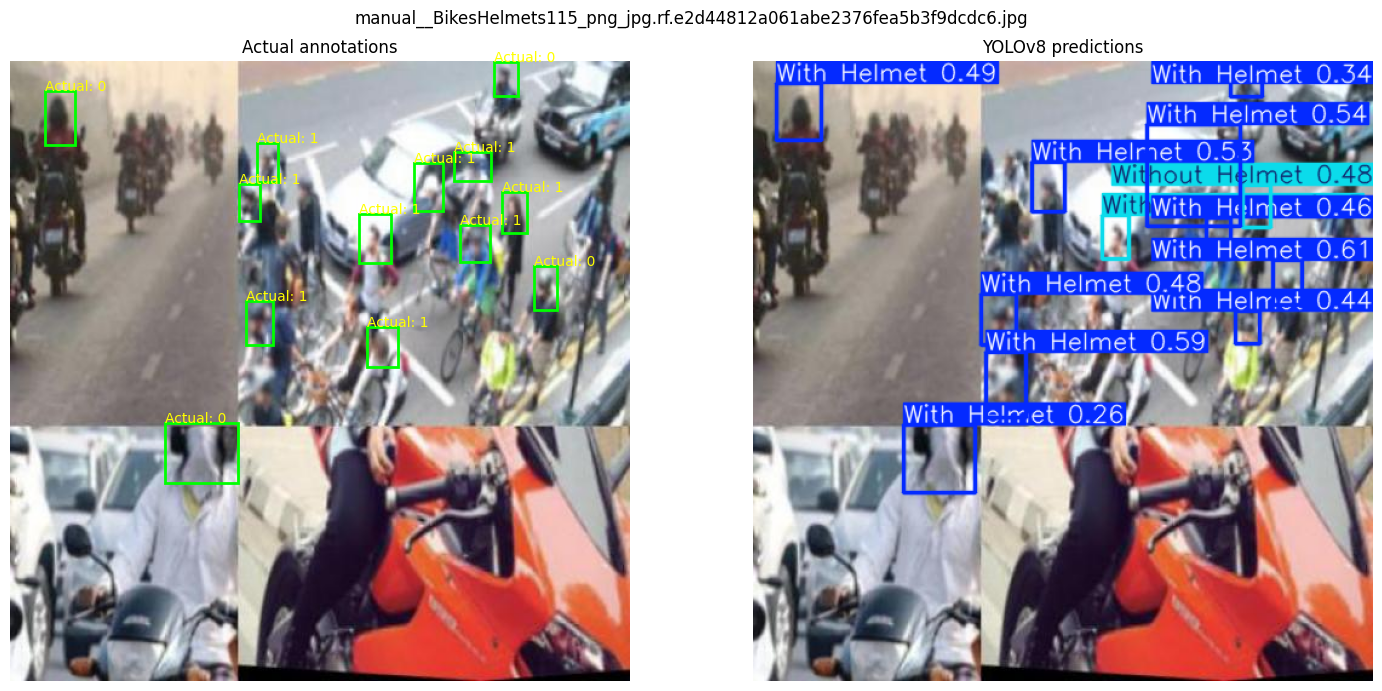

Image: manual__BikesHelmets115_png_jpg.rf.e2d44812a061abe2376fea5b3f9dcdc6.jpg


,Image,Actual,Prediction,Confidence,IoU,Error Type
5,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,Without Helmet,With Helmet,0.478,0.673,Wrong class
6,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,Without Helmet,With Helmet,0.456,0.668,Wrong class
8,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,No matched object,With Helmet,0.587,-,False Positive
9,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,No matched object,With Helmet,0.54,-,False Positive
10,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,No matched object,With Helmet,0.53,-,False Positive
11,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,No matched object,With Helmet,0.444,-,False Positive
12,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,Without Helmet,Not detected,-,-,False Negative
13,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,Without Helmet,Not detected,-,-,False Negative
14,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,Without Helmet,Not detected,-,-,False Negative
15,manual__BikesHelmets115_png_jpg.rf.e2d44812a06...,Without Helmet,Not detected,-,-,False Negative


In [35]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
from ultralytics import YOLO

base = Path("/content/drive/MyDrive/cv_project/dataset/final_dataset")
image_dir = base / "images/test"
label_dir = base / "labels/test"

model = YOLO(
    "/content/drive/MyDrive/cv_project/models/best.pt"
)

# Pehli image jisme error record hua
error_rows = df[df["Error Type"] != "Correct detection"]
filename = error_rows.iloc[0]["Image"]

image_path = image_dir / filename
label_path = label_dir / (image_path.stem + ".txt")

image = Image.open(image_path).convert("RGB")
width, height = image.size

# Actual annotations
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

axes[0].imshow(image)
if label_path.exists():
    for line in label_path.read_text().splitlines():
        cls, xc, yc, bw, bh = map(float, line.split())
        x1, y1 = (xc-bw/2)*width, (yc-bh/2)*height
        x2, y2 = (xc+bw/2)*width, (yc+bh/2)*height
        axes[0].add_patch(plt.Rectangle(
            (x1, y1), x2-x1, y2-y1,
            fill=False, edgecolor="lime", linewidth=2
        ))
        axes[0].text(x1, y1, f"Actual: {int(cls)}", color="yellow")

axes[0].set_title("Actual annotations")

# Model predictions
result = model.predict(image, imgsz=640, conf=0.25, verbose=False)[0]
axes[1].imshow(result.plot()[:, :, ::-1])
axes[1].set_title("YOLOv8 predictions")

for ax in axes:
    ax.axis("off")

plt.suptitle(filename)
plt.tight_layout()
plt.show()

print("Image:", filename)
display(error_rows[error_rows["Image"] == filename])
